# VVI quickstart

From dated exposure histories to hazard ratios, waning and power — on a **synthetic**
cohort. Nothing in this notebook touches real data.

In [1]:
import matplotlib
import numpy as np
import vvi
from vvi import plots as P

P.fonts();  # register the bundled fonts
print("vvi", vvi.__version__)

vvi 0.2.0


## 1 · A cohort and its histories

`simulate` draws people, their profile, the day of their last exposure (`anchor`) and
recurrent infections in calendar time. `histories` back-fills dated doses and infections
consistent with each profile; `encode_table` turns them back into profiles.

In [2]:
cohort = vvi.simulate(200_000, seed=1)
history = vvi.histories(cohort, seed=1)
history.head(7)

,id,day,kind
0,0,-475,Comirnaty
1,0,-447,Comirnaty
2,0,-254,Comirnaty
3,0,-81,infection
4,1,-685,CoronaVac
5,1,-654,CoronaVac
6,1,-404,CoronaVac


In [3]:
profiles = vvi.encode_table(history)
print("round-trip exact:", bool((profiles == cohort.people.set_index("id")["profile"]).all()))
profiles.value_counts()

round-trip exact: True


profile
BBB     48363
SSS     43891
SS      23974
BB      23837
BBBI    19919
SSSI    15932
SSI     12057
BBI     12027
Name: count, dtype: int64

## 2 · A ledger instead of a panel

The fit only needs people at risk and events per covariate cell and calendar day.

In [4]:
ledger = vvi.aggregate(cohort.people, cohort.events, horizon=365, blank_days=28)
print(f"{ledger['at_risk'].sum():,} person-days -> {len(ledger):,} rows")
ledger.head()

62,811,773 person-days -> 17,520 rows


,profile,sex,age_band,day,at_risk,events
0,BBBI,M,18-59,0,55,0
1,BBBI,M,18-59,1,125,0
2,BBBI,M,18-59,2,201,0
3,BBBI,M,18-59,3,268,0
4,BBBI,M,18-59,4,330,0


## 3 · Fit, hazard ratios, the imprinting contrast

In [5]:
fit = vvi.fit(ledger, reference="BB", df=7)
fit.table().round(3)

,term,log_hr,se,hr,ci_low,ci_high,pe,p
0,BBB,-0.486,0.030,0.615,0.580,0.652,0.385,0.000
1,BBBI,-1.294,0.051,0.274,0.248,0.303,0.726,0.000
2,BBI,-1.555,0.071,0.211,0.184,0.242,0.789,0.000
3,SS,0.220,0.030,1.246,1.175,1.320,-0.246,0.000
4,SSI,-1.306,0.063,0.271,0.239,0.307,0.729,0.000
5,SSS,-0.122,0.028,0.885,0.838,0.935,0.115,0.000
6,SSSI,-1.424,0.059,0.241,0.215,0.270,0.759,0.000
7,sex: M,0.061,0.018,1.063,1.026,1.102,-0.063,0.001
8,age_band: 60-79,-0.176,0.021,0.839,0.805,0.874,0.161,0.000
9,age_band: 80+,-0.233,0.037,0.792,0.737,0.852,0.208,0.000


In [6]:
c = fit.contrast("BBBI", "BBI")
lo, hi = c.ci
truth = cohort.truth.profile_effects
print(f"BBBI vs BBI: HR {c.hr:.2f} (95% CI {lo:.2f}-{hi:.2f}), "
      f"planted {np.exp(truth['BBBI'] - truth['BBI']):.2f}")

BBBI vs BBI: HR 1.30 (95% CI 1.11-1.52), planted 1.28


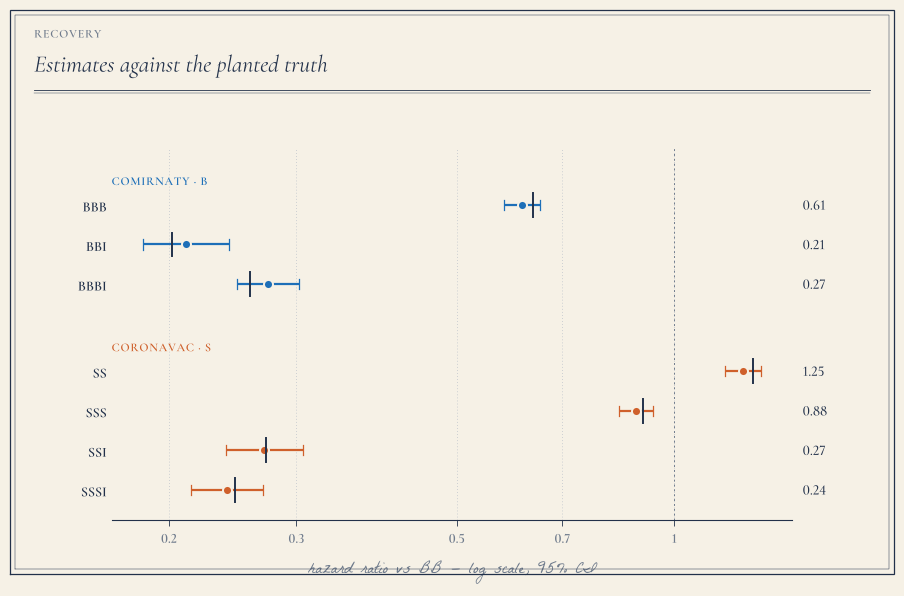

In [7]:
fig = P.plate((9.2, 6.0), kicker="Recovery", title="Estimates against the planted truth")
ax = fig.add_axes([0.13, 0.12, 0.74, 0.62])
P.forest(fit, ax, truth=truth);

## 4 · Waning: a covariate that changes during follow-up

In [8]:
wcohort = vvi.simulate(300_000, seed=2, truth=vvi.Truth(waning=vvi.WANING_EXAMPLE))
bands = vvi.Bands()
wledger = vvi.aggregate(wcohort.people, wcohort.events, horizon=365, bands=bands)
wfit = vvi.fit(wledger, reference="BB", covariates=("sex", "age_band", "since"))
[(e.term, round(e.hr, 3), round(np.exp(vvi.WANING_EXAMPLE[e.term]), 3))
 for e in wfit.covariate_effects("since")]

[('0-89d', 1.0, np.float64(1.0)),
 ('90-179d', 1.228, np.float64(1.284)),
 ('180-269d', 1.506, np.float64(1.568)),
 ('270d+', 1.746, np.float64(1.822))]

## 5 · How many people would a smaller effect need?

In [9]:
sizes = [100_000, 300_000, 1_000_000, 1_500_000]
for hr in (1.1, 1.2, 1.3):
    pw = vvi.power(c, n_fit=200_000, sizes=sizes, log_hr=np.log(hr))
    need = vvi.required_size(c, n_fit=200_000, log_hr=np.log(hr))
    print(f"HR {hr}: power " + ", ".join(f"{n/1e3:.0f}k {p:.0%}" for n, p in zip(sizes, pw))
          + f"  |  80% needs {need:,}")

HR 1.1: power 100k 13%, 300k 30%, 1000k 75%, 1500k 89%  |  80% needs 1,140,682
HR 1.2: power 100k 35%, 300k 78%, 1000k 100%, 1500k 100%  |  80% needs 311,722
HR 1.3: power 100k 63%, 300k 98%, 1000k 100%, 1500k 100%  |  80% needs 150,534
